# Proteomics CoPYlot

HEK293 protein and phosphosite analysis. WT versus GRK, five replicates per condition.

Tables below the plots show up to ten rows for large results. The named variables contain the full tables.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from proteomicscopylot import notebook_functions as pcp

## Inputs and settings

Run all cells for the bundled example. For custom data, set `use_example = False`, enter your paths and choose `linear` or `log2` for each table. Each metadata CSV needs `sample` and `condition` columns. For protein-only data, stop after **Save protein results**.

In [2]:
use_example = True
protein_file, protein_metadata_file = "proteins.tsv", "protein_metadata.csv"
site_file, site_metadata_file = "sites.tsv", "site_metadata.csv"
protein_scale, site_scale = "log2", "log2"

conditions = ["WT", "GRK"]  # positive log2 fold change = higher in the first group
min_present, filter_mode = 3, "per_group"
test_type = "unpaired"  # unpaired, unpaired_welch, or paired (requires pair_id)
imputation_seed = 1
filter_protein_contaminants = True
filter_phospho_contaminants = True
contaminant_categories = [1, 2, 3, 4, 5]
localization_cutoff = 0.0  # 0.75 for Class I sites
organism = "human"  # human or mouse for GO enrichment
output_dir = None  # set to Path("copylot-results") to write tables and figures

In [3]:
def read_inputs(table_path, metadata_path, scale):
    table = pcp.read_data(table_path)
    metadata = pd.read_csv(metadata_path, dtype=str)
    if not {"sample", "condition"}.issubset(metadata):
        raise ValueError("Metadata needs sample and condition columns.")
    samples = metadata["sample"]
    if metadata[["sample", "condition"]].isna().any().any() or samples.duplicated().any():
        raise ValueError("Each sample needs one unique name and a condition.")
    missing = samples[~samples.isin(table.columns)].tolist()
    if missing:
        raise ValueError(f"Metadata sample names missing from the table: {missing}")
    if len(conditions) != 2 or len(set(conditions)) != 2 or not set(conditions) <= set(metadata["condition"]):
        raise ValueError("Choose two different conditions present in the metadata.")
    if scale == "linear":
        table = pcp.log2_transform_data(table, metadata)  # linear zero is missing
    elif scale == "log2":
        table[samples] = table[samples].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    else:
        raise ValueError("Input scale must be 'linear' or 'log2'.")
    return table, metadata

if use_example:
    protein_inputs = (pcp.example_data_path("protein"), pcp.example_data_path("protein_metadata"), "log2")
    site_inputs = (pcp.example_data_path("phospho"), pcp.example_data_path("phospho_metadata"), "log2")
else:
    protein_inputs = (protein_file, protein_metadata_file, protein_scale)
    site_inputs = (site_file, site_metadata_file, site_scale) if site_file is not None else None

data, meta = read_inputs(*protein_inputs)
print(f"{len(data):,} protein rows; replicates per condition:")
meta["condition"].value_counts()

7,490 protein rows; replicates per condition:


,count
condition,
WT,5
GRK,5


## Filter proteins

In [4]:
filtered = pcp.filter_data(data, meta, min_present, mode=filter_mode)
filtered = pcp.filter_contaminants(filtered, enabled=filter_protein_contaminants, categories=contaminant_categories)
if filtered.empty:
    raise ValueError("No proteins remain; revise the filters.")
print(f"{len(filtered):,} of {len(data):,} proteins retained")

7,365 of 7,490 proteins retained


## Protein completeness

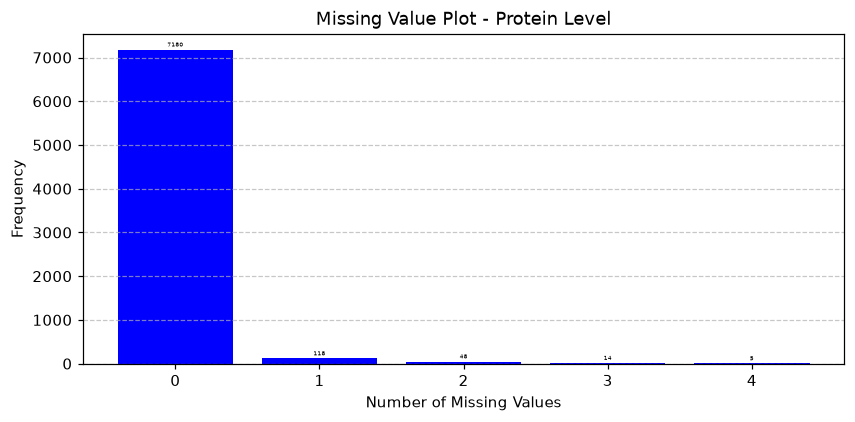

In [5]:
fig = pcp.missing_value_plot(filtered, meta, data_scale="log2")

In [6]:
missing_features = pcp.missing_protein_table(filtered, meta, id=False)
missing_features.head(10)

,n_MissingProteinValues,Counts,%_missing_values
0,0,7180,97.488119
1,1,118,1.602172
2,2,48,0.651731
3,3,14,0.190088
4,4,5,0.067889


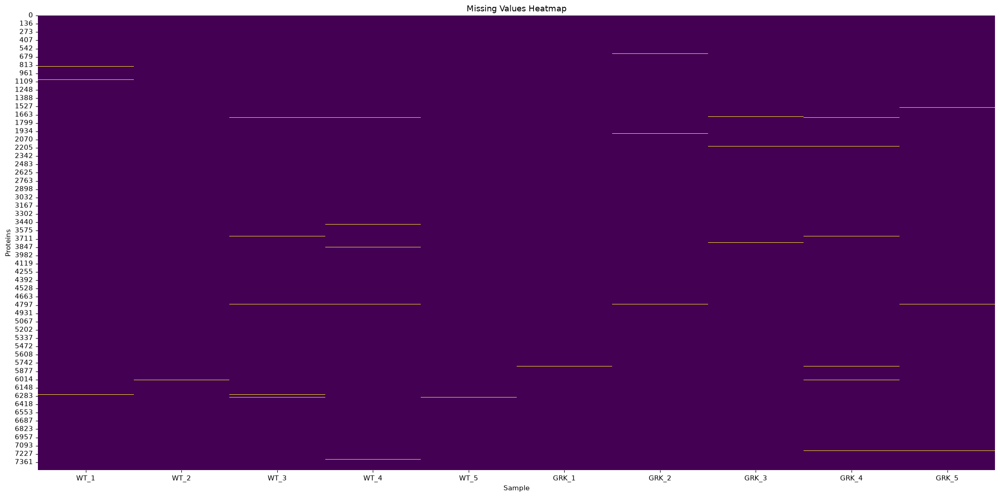

In [7]:
fig = pcp.missing_value_heatmap(filtered, meta, id=False, data_scale="log2")

In [8]:
pcp.missing_sample_table(filtered, meta, id=False, data_scale="log2")

,Sample,Counts,%_missing_values
0,WT_1,22,0.298710
1,WT_2,35,0.475221
2,WT_3,29,0.393754
3,WT_4,32,0.434487
4,WT_5,19,0.257977
5,GRK_1,24,0.325866
6,GRK_2,23,0.312288
7,GRK_3,23,0.312288
8,GRK_4,33,0.448065
9,GRK_5,36,0.488798


## Imputation

In [9]:
imputed = pcp.impute_values(filtered, meta, seed=imputation_seed)

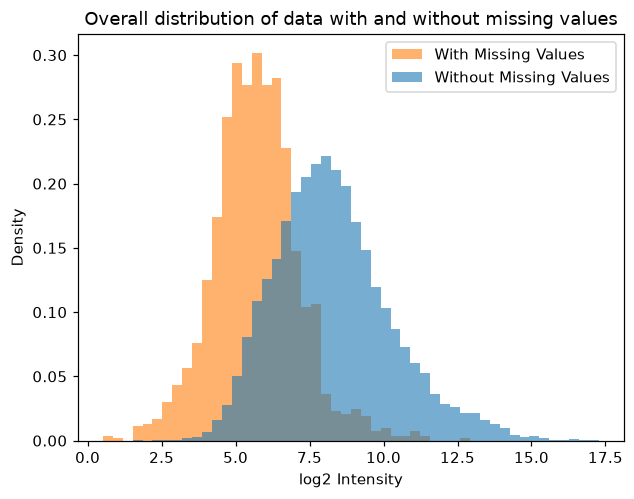

In [10]:
fig = pcp.impute_values(filtered, meta, ret=1, seed=imputation_seed)

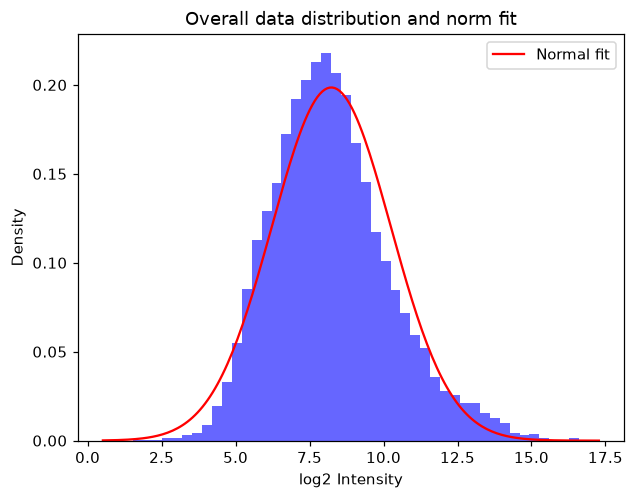

In [11]:
fig = pcp.impute_values(filtered, meta, ret=2, seed=imputation_seed)

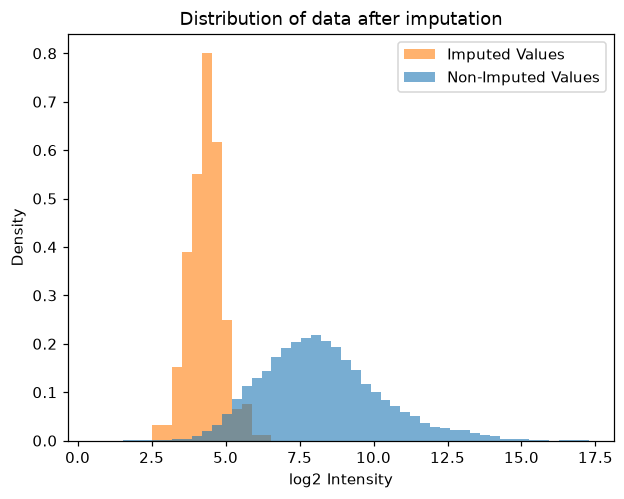

In [12]:
fig = pcp.impute_values(filtered, meta, ret=3, seed=imputation_seed)

In [13]:
imputed.head(10)

,PG.ProteinAccessions,GeneNames,PG.ProteinDescriptions,ProteinNames,PG.IsCandidate,PG.Completeness,PG.CV,...,[4] 20240822_nElute_tims1_JM_HEK293_WP_GRK_4_Slot1-76_1_8073.d.PG.Log2Quantity,[5] 20240822_nElute_tims1_JM_HEK293_WP_GRK_5_Slot1-77_1_8074.d.PG.Log2Quantity,[6] 20240822_nElute_tims1_JM_HEK293_WP_WT_1_Slot1-61_1_8064.d.PG.Log2Quantity,[7] 20240822_nElute_tims1_JM_HEK293_WP_WT_2_Slot1-62_1_8065.d.PG.Log2Quantity,[8] 20240822_nElute_tims1_JM_HEK293_WP_WT_3_Slot1-63_1_8066.d.PG.Log2Quantity,[9] 20240822_nElute_tims1_JM_HEK293_WP_WT_4_Slot1-64_1_8067.d.PG.Log2Quantity,[10] 20240822_nElute_tims1_JM_HEK293_WP_WT_5_Slot1-65_1_8068.d.PG.Log2Quantity
0,A0A024R1R8;Q9Y2S6,TMA7B;TMA7,Translation machinery-associated protein 7B;Translation machinery-associated protein 7,TMA7B_HUMAN;TMA7_HUMAN,False,100,0.145776,...,11.060520,11.077355,10.994232,10.844383,11.101420,10.766157,11.326016
1,A0A024RBG1,NUDT4B,Diphosphoinositol polyphosphate phosphohydrolase NUDT4B,NUD4B_HUMAN,False,100,0.127925,...,7.304700,7.130278,7.594481,6.983359,7.132668,7.029703,7.253822
2,A0A096LP01,SMIM26,Small integral membrane protein 26,SIM26_HUMAN,True,90,0.463910,...,4.089103,5.435773,4.070345,4.798248,3.913111,3.914092,3.754654
3,A0A0B4J2A2,PPIAL4C,Peptidyl-prolyl cis-trans isomerase A-like 4C,PAL4C_HUMAN,False,100,0.063728,...,14.935593,14.916440,14.899020,15.018666,15.072172,14.978788,15.118971
4,A0A0B4J2D5;P0DPI2,GATD3B;GATD3,"Putative glutamine amidotransferase-like class 1 domain-containing protein 3B, mitochondrial;Glutamine amidotransferase-like class 1 domain-containing protein 3, mitochondrial",GAL3B_HUMAN;GAL3A_HUMAN,False,100,0.059058,...,10.876051,10.835884,10.985315,10.931394,11.063448,10.973523,10.999265
5,A0A0B4J2F0,PIGBOS1,Protein PIGBOS1,PIOS1_HUMAN,False,90,0.089025,...,6.985543,6.728044,6.938165,6.687953,7.038812,6.704645,6.802161
6,A0A0U1RRE5,NBDY,Negative regulator of P-body association,NBDY_HUMAN,False,100,0.199200,...,7.034911,7.485326,7.492033,7.274410,6.590410,7.579566,7.405431
7,A0A1W2PPL8,TAF11L14,TATA-box-binding protein-associated factor 11-like protein 14,TFKLN_HUMAN,False,100,0.062838,...,8.793927,8.765254,8.840576,8.924339,8.951169,8.761025,8.872300
8,A0A2Z4LIS9,FOXO3B,Forkhead box protein O3B,FXO3B_HUMAN,False,90,0.122353,...,5.610011,6.619963,6.749627,6.896288,6.625096,6.610302,6.290848
9,A0A499FJF3;Q6P4F7,;ARHGAP11A,Rho-GAP domain-containing protein;Rho GTPase-activating protein 11A,A0A499FJF3_HUMAN;RHGBA_HUMAN,False,100,0.260735,...,5.965501,5.370451,6.011989,6.545594,6.555304,6.203158,5.649741


## QC

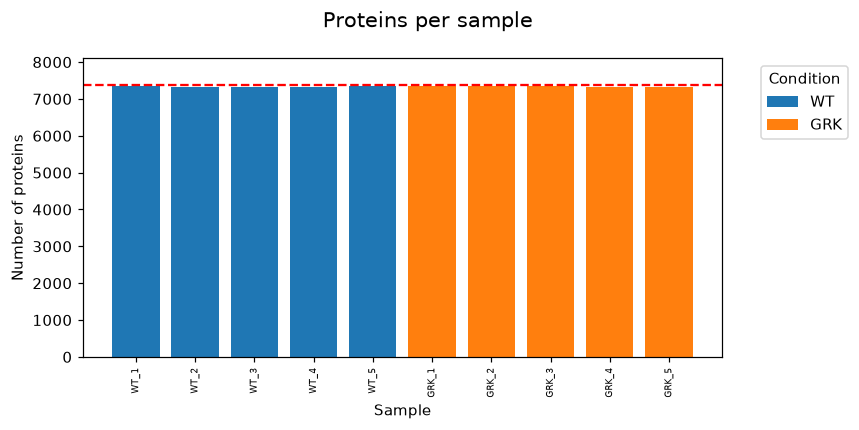

In [14]:
linear = pcp.inverse_log2_transform_data(filtered, meta)
fig = pcp.coverage_plot(filtered, meta, id=False, data_scale="log2")

In [15]:
coverage = pcp.qc_coverage_table(filtered, meta)
coverage

,Sample,Number
0,WT_1,7343
1,WT_2,7330
2,WT_3,7336
3,WT_4,7333
4,WT_5,7346
5,GRK_1,7341
6,GRK_2,7342
7,GRK_3,7342
8,GRK_4,7332
9,GRK_5,7329


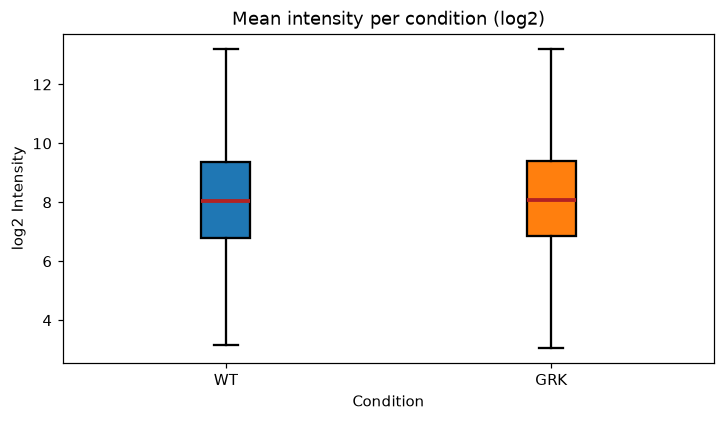

In [16]:
fig = pcp.boxplot_int(filtered, meta, data_scale="log2")

In [17]:
intensity_summary = pcp.qc_boxplot_table(filtered, meta)
intensity_summary.head(10)

,Condition,mean,median,Q1,Q3,lower_whisker,upper_whisker
0,WT,8.21,8.03,6.79,9.35,3.17,13.19
1,GRK,8.24,8.07,6.85,9.40,3.07,13.21


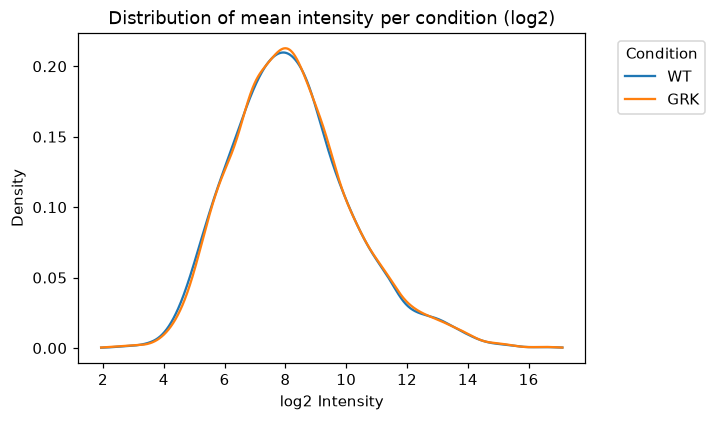

In [18]:
fig = pcp.histo_int(filtered, meta, data_scale="log2")

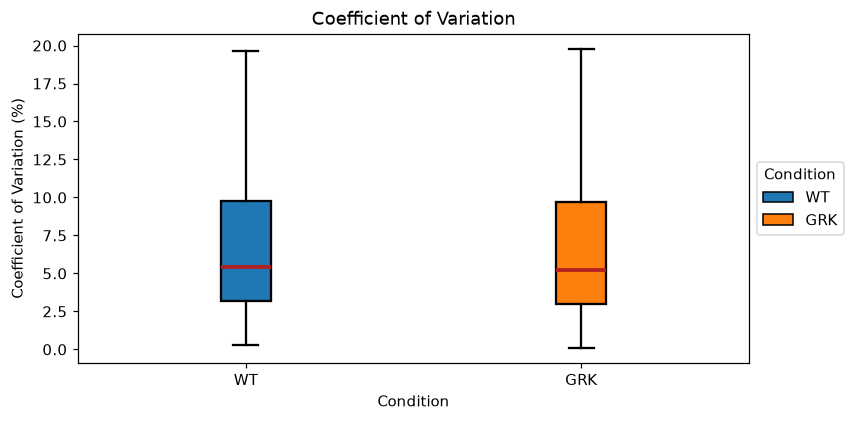

In [19]:
fig = pcp.cov_plot(linear, meta, data_scale="linear")

In [20]:
cv_summary = pcp.qc_cv_table(linear, meta)
cv_summary.head(10)

,Condition,mean,median,Q1,Q3,lower_whisker,upper_whisker
0,WT,7.64,5.43,3.15,9.74,0.27,19.63
1,GRK,7.62,5.25,2.97,9.70,0.11,19.78


In [21]:
feature_cvs = pcp.qc_feature_cvs(linear, meta)
feature_cvs.head(10)

,PG.ProteinAccessions,GeneNames,PG.ProteinDescriptions,ProteinNames,PG.IsCandidate,PG.Completeness,PG.CV,PG.AvgLog2Quantity,WT CV (%),GRK CV (%)
0,A0A024R1R8;Q9Y2S6,TMA7B;TMA7,Translation machinery-associated protein 7B;Translation machinery-associated protein 7,TMA7B_HUMAN;TMA7_HUMAN,False,100,0.145776,10.955714,15.704756,13.981300
1,A0A024RBG1,NUDT4B,Diphosphoinositol polyphosphate phosphohydrolase NUDT4B,NUD4B_HUMAN,False,100,0.127925,7.208081,18.074483,6.496326
2,A0A096LP01,SMIM26,Small integral membrane protein 26,SIM26_HUMAN,True,90,0.463910,4.341089,32.884431,46.587926
3,A0A0B4J2A2,PPIAL4C,Peptidyl-prolyl cis-trans isomerase A-like 4C,PAL4C_HUMAN,False,100,0.063728,14.955302,5.846171,2.670892
4,A0A0B4J2D5;P0DPI2,GATD3B;GATD3,"Putative glutamine amidotransferase-like class 1 domain-containing protein 3B, mitochondrial;Glutamine amidotransferase-like class 1 domain-containing protein 3, mitochondrial",GAL3B_HUMAN;GAL3A_HUMAN,False,100,0.059058,10.922483,3.347472,3.415500
5,A0A0B4J2F0,PIGBOS1,Protein PIGBOS1,PIOS1_HUMAN,False,90,0.089025,6.848775,10.657587,7.632182
6,A0A0U1RRE5,NBDY,Negative regulator of P-body association,NBDY_HUMAN,False,100,0.199200,7.337941,23.481856,17.794149
7,A0A1W2PPL8,TAF11L14,TATA-box-binding protein-associated factor 11-like protein 14,TFKLN_HUMAN,False,100,0.062838,8.876614,5.123573,7.841854
8,A0A2Z4LIS9,FOXO3B,Forkhead box protein O3B,FXO3B_HUMAN,False,90,0.122353,6.586045,14.966636,5.406155
9,A0A499FJF3;Q6P4F7,;ARHGAP11A,Rho-GAP domain-containing protein;Rho GTPase-activating protein 11A,A0A499FJF3_HUMAN;RHGBA_HUMAN,False,100,0.260735,6.003350,25.132529,18.055524


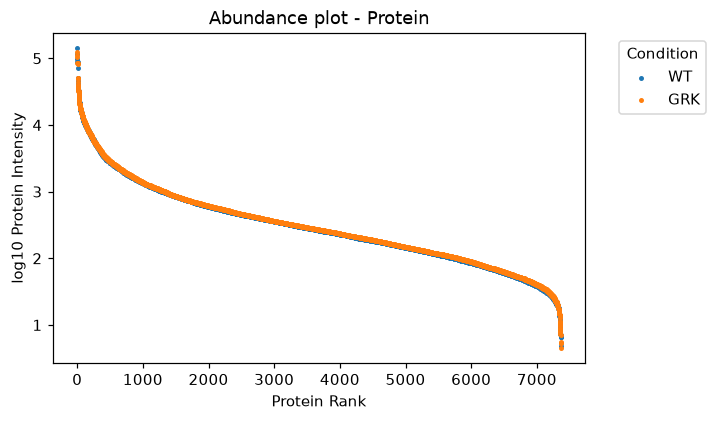

In [22]:
fig = pcp.abundance_plot(linear, meta, workflow="Protein", data_scale="linear")

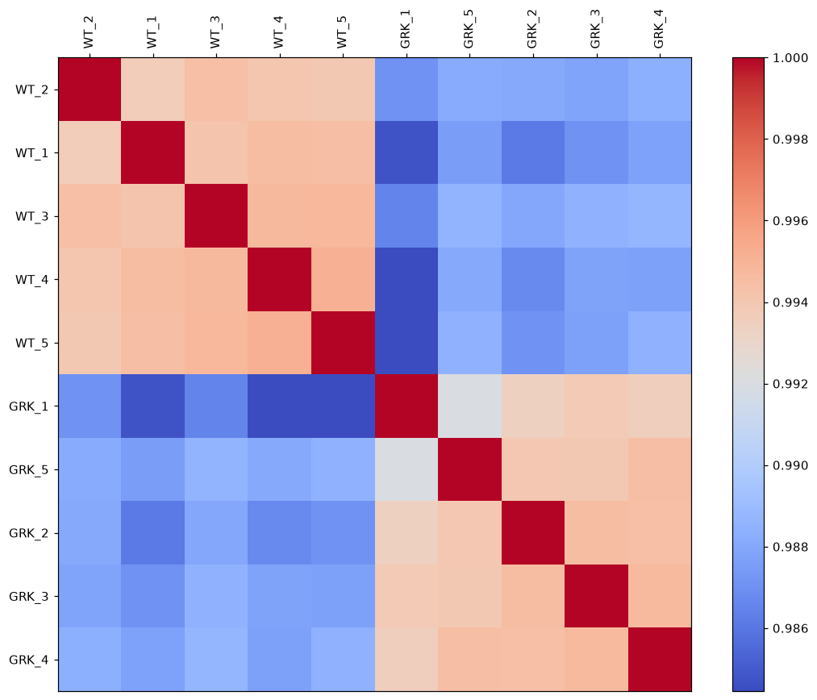

In [23]:
fig = pcp.corr_plot(filtered, meta, id=False, data_scale="log2")

In [24]:
correlations = pcp.sample_correlation_matrix(filtered, meta, id=False)
correlations.head(10)

,WT_1,WT_2,WT_3,WT_4,WT_5,GRK_1,GRK_2,GRK_3,GRK_4,GRK_5
WT_1,1.000000,0.993656,0.994210,0.994580,0.994489,0.984704,0.986094,0.987019,0.987676,0.987515
WT_2,0.993656,1.000000,0.994436,0.994080,0.993974,0.987011,0.988061,0.987840,0.988397,0.988157
WT_3,0.994210,0.994436,1.000000,0.994727,0.994830,0.986477,0.987915,0.988481,0.988697,0.988554
WT_4,0.994580,0.994080,0.994727,1.000000,0.995171,0.984463,0.986759,0.987779,0.987614,0.988078
WT_5,0.994489,0.993974,0.994830,0.995171,1.000000,0.984453,0.987102,0.987612,0.988419,0.988511
GRK_1,0.984704,0.987011,0.986477,0.984463,0.984453,1.000000,0.993421,0.993863,0.993512,0.992039
GRK_2,0.986094,0.988061,0.987915,0.986759,0.987102,0.993421,1.000000,0.994565,0.994451,0.994030
GRK_3,0.987019,0.987840,0.988481,0.987779,0.987612,0.993863,0.994565,1.000000,0.994663,0.993928
GRK_4,0.987676,0.988397,0.988697,0.987614,0.988419,0.993512,0.994451,0.994663,1.000000,0.994488
GRK_5,0.987515,0.988157,0.988554,0.988078,0.988511,0.992039,0.994030,0.993928,0.994488,1.000000


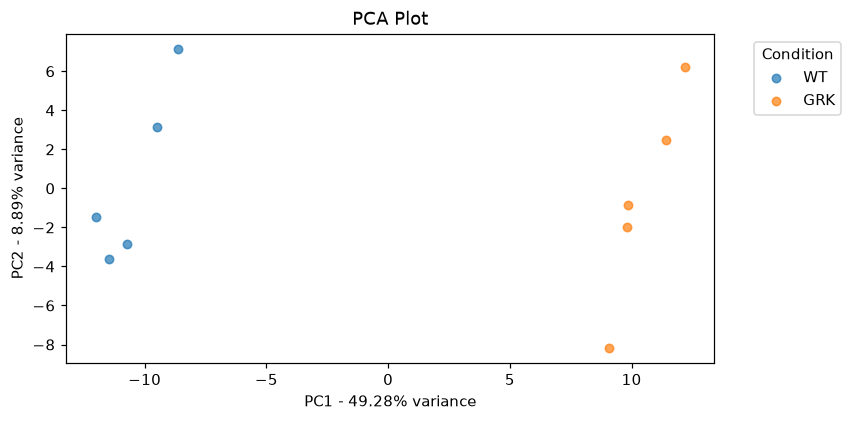

In [25]:
pca_figure = pcp.pca_plot(filtered, meta)

In [26]:
scores = pcp.pca_scores(filtered, meta)
scores.head(10)

,PC1,PC2,sample,condition
0,-12.017308,-1.490276,[6] 20240822_nElute_tims1_JM_HEK293_WP_WT_1_Slot1-61_1_8064.d.PG.Log2Quantity,WT
1,-8.639291,7.149434,[7] 20240822_nElute_tims1_JM_HEK293_WP_WT_2_Slot1-62_1_8065.d.PG.Log2Quantity,WT
2,-9.495688,3.137364,[8] 20240822_nElute_tims1_JM_HEK293_WP_WT_3_Slot1-63_1_8066.d.PG.Log2Quantity,WT
3,-11.459925,-3.604749,[9] 20240822_nElute_tims1_JM_HEK293_WP_WT_4_Slot1-64_1_8067.d.PG.Log2Quantity,WT
4,-10.732265,-2.851199,[10] 20240822_nElute_tims1_JM_HEK293_WP_WT_5_Slot1-65_1_8068.d.PG.Log2Quantity,WT
5,12.188884,6.206170,[1] 20240822_nElute_tims1_JM_HEK293_WP_GRK_1_Slot1-73_1_8070.d.PG.Log2Quantity,GRK
6,11.430007,2.463150,[2] 20240822_nElute_tims1_JM_HEK293_WP_GRK_2_Slot1-74_1_8071.d.PG.Log2Quantity,GRK
7,9.791461,-1.996639,[3] 20240822_nElute_tims1_JM_HEK293_WP_GRK_3_Slot1-75_1_8072.d.PG.Log2Quantity,GRK
8,9.852282,-0.849817,[4] 20240822_nElute_tims1_JM_HEK293_WP_GRK_4_Slot1-76_1_8073.d.PG.Log2Quantity,GRK
9,9.081842,-8.163438,[5] 20240822_nElute_tims1_JM_HEK293_WP_GRK_5_Slot1-77_1_8074.d.PG.Log2Quantity,GRK


## Differential abundance

In [27]:
volcano = pcp.volcano_data_f(filtered, meta, *conditions, workflow="Protein", test_type=test_type)
volcano["significance"].value_counts()

,count
significance,
Not significant,7306
Downregulated,51
Upregulated,8


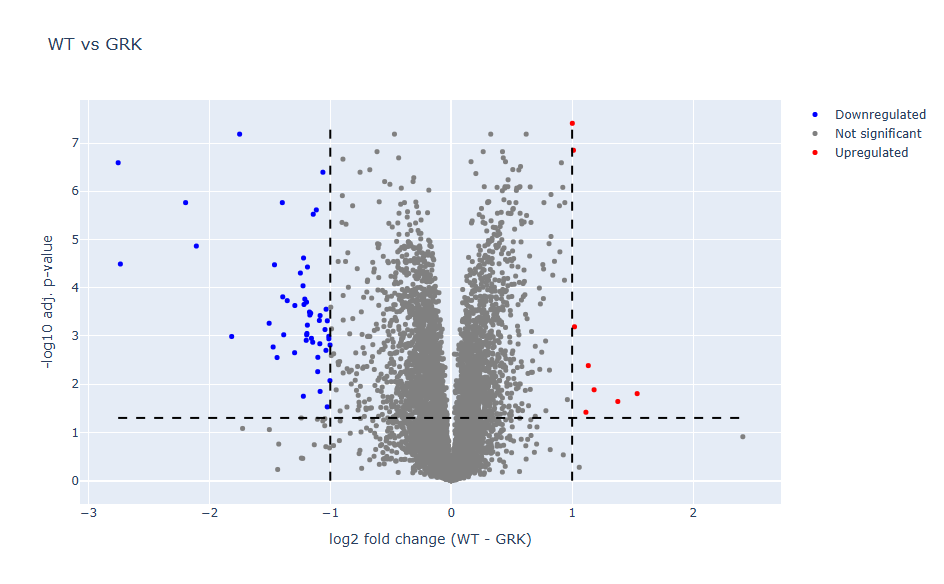

In [28]:
fig = pcp.volcano_plot(volcano, *conditions)
fig.show()

In [29]:
volcano.head(10)

,ProteinNames,log2FC,pval,adj_pval,selected_pval,significance,neg_log10_selected_pval,zero_variance,se,dof
0,TMA7B_HUMAN;TMA7_HUMAN,0.101455,0.482330,0.597437,0.597437,Not significant,0.223708,False,0.137710,8.0
1,NUD4B_HUMAN,-0.018550,0.877902,0.915569,0.915569,Not significant,0.038309,False,0.116949,8.0
2,SIM26_HUMAN,-0.564747,0.162496,0.261012,0.261012,Not significant,0.583339,False,0.361789,7.0
3,PAL4C_HUMAN,0.124443,0.017538,0.045577,0.045577,Not significant,1.341256,False,0.041727,8.0
4,GAL3B_HUMAN;GAL3A_HUMAN,0.136213,0.002264,0.009126,0.009126,Not significant,2.039710,False,0.030905,8.0
5,PIOS1_HUMAN,-0.032462,0.731895,0.810280,0.810280,Not significant,0.091365,False,0.091032,7.0
6,NBDY_HUMAN,-0.139142,0.532735,0.642356,0.642356,Not significant,0.192224,False,0.213436,8.0
7,TFKLN_HUMAN,-0.013464,0.829192,0.878958,0.878958,Not significant,0.056032,False,0.060402,8.0
8,FXO3B_HUMAN,0.108872,0.389217,0.509977,0.509977,Not significant,0.292449,False,0.118614,7.0
9,A0A499FJF3_HUMAN;RHGBA_HUMAN,0.379614,0.110014,0.192675,0.192675,Not significant,0.715174,False,0.211219,8.0


In [30]:
protein_untested = pcp.volcano_untested_table(filtered, meta, *conditions, kind="protein", paired=test_type == "paired")
protein_untested.head(10)

,ProteinNames,GeneNames,n_WT,mean_WT,n_GRK,mean_GRK,reason


In [31]:
welch = pcp.volcano_data_f(filtered, meta, *conditions, workflow="Protein", test_type="unpaired_welch")
welch["significance"].value_counts()

,count
significance,
Not significant,7308
Downregulated,50
Upregulated,7


In [32]:
volcano_imputed = pcp.volcano_data_f(imputed, meta, *conditions, workflow="Protein", observed=filtered, test_type=test_type)
volcano_imputed[["ProteinNames", "log2FC", "adj_pval", "imputed_values"]].head()

,ProteinNames,log2FC,adj_pval,imputed_values
0,TMA7B_HUMAN;TMA7_HUMAN,0.101455,0.597236,0
1,NUD4B_HUMAN,-0.018550,0.916348,0
2,SIM26_HUMAN,-0.397651,0.421432,1
3,PAL4C_HUMAN,0.124443,0.045706,0
4,GAL3B_HUMAN;GAL3A_HUMAN,0.136213,0.009146,0


## ANOVA

In [33]:
anova = pcp.anova_data_f(filtered, meta)

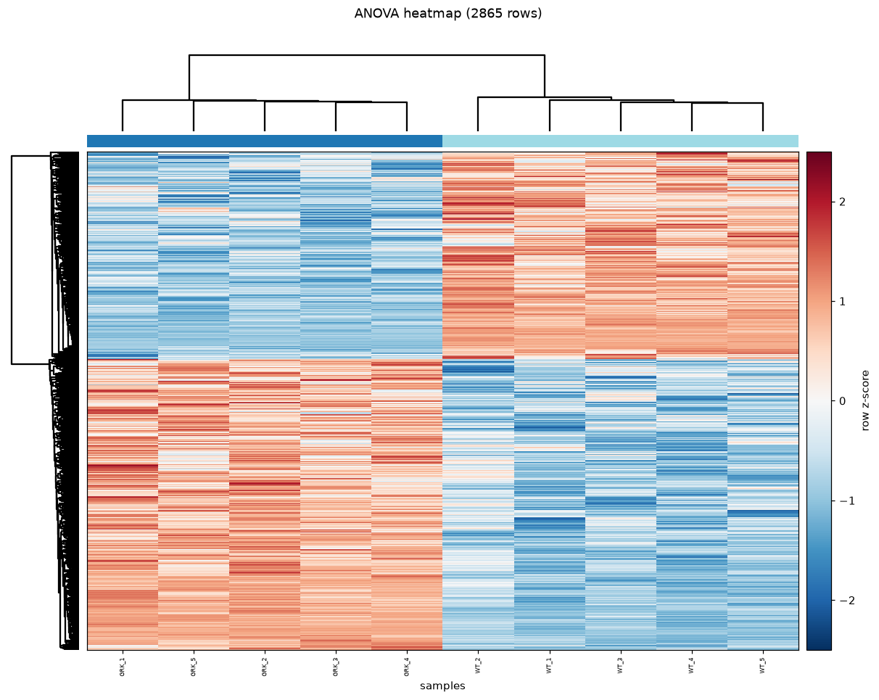

In [34]:
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=r".*features dropped for clustering", category=RuntimeWarning)
    fig = pcp.anova_plot(anova, meta)

In [35]:
anova.head(10)

,ProteinNames,[6] 20240822_nElute_tims1_JM_HEK293_WP_WT_1_Slot1-61_1_8064.d.PG.Log2Quantity,[7] 20240822_nElute_tims1_JM_HEK293_WP_WT_2_Slot1-62_1_8065.d.PG.Log2Quantity,[8] 20240822_nElute_tims1_JM_HEK293_WP_WT_3_Slot1-63_1_8066.d.PG.Log2Quantity,[9] 20240822_nElute_tims1_JM_HEK293_WP_WT_4_Slot1-64_1_8067.d.PG.Log2Quantity,[10] 20240822_nElute_tims1_JM_HEK293_WP_WT_5_Slot1-65_1_8068.d.PG.Log2Quantity,[1] 20240822_nElute_tims1_JM_HEK293_WP_GRK_1_Slot1-73_1_8070.d.PG.Log2Quantity,...,adj_pval,selected_pval,significance,neg_log10_selected_pval,zero_variance,mean_WT,mean_GRK
0,NFM_HUMAN,13.199075,13.236867,13.197604,13.192854,13.192777,12.220782,...,3.907678e-08,3.907678e-08,Significant,7.408081,False,13.203836,12.202036
1,PO210_HUMAN,8.515957,8.553875,8.526207,8.534052,8.527627,8.991295,...,6.549567e-08,6.549567e-08,Significant,7.183787,False,8.531544,9.000800
2,AKA12_HUMAN,9.835697,9.874645,9.828794,9.813231,9.810984,9.224510,...,6.549567e-08,6.549567e-08,Significant,7.183787,False,9.832670,9.212691
3,MCM7_HUMAN,11.909185,11.914336,11.919487,11.923496,11.893413,11.595979,...,6.549567e-08,6.549567e-08,Significant,7.183787,False,11.911983,11.584953
4,ANXA3_HUMAN,7.559820,7.593566,7.615124,7.556953,7.446073,9.241310,...,6.549567e-08,6.549567e-08,Significant,7.183787,False,7.554307,9.304079
5,NFL_HUMAN,12.513494,12.566690,12.543939,12.513951,12.499454,11.546075,...,1.415339e-07,1.415339e-07,Significant,6.849140,False,12.527506,11.516474
6,INO1_HUMAN,9.910885,9.948204,9.912126,9.927973,9.920251,10.553664,...,1.512069e-07,1.512069e-07,Significant,6.820428,False,9.923888,10.537396
7,PRDX6_HUMAN,13.931296,13.949980,13.949348,13.952253,13.924641,13.676050,...,1.512069e-07,1.512069e-07,Significant,6.820428,False,13.941503,13.676920
8,ANXA2_HUMAN,13.353599,13.391924,13.399077,13.363297,13.366568,12.967037,...,1.512069e-07,1.512069e-07,Significant,6.820428,False,13.374893,12.950715
9,SYIM_HUMAN,10.007660,10.010733,9.995062,9.994108,10.047544,9.585726,...,2.032054e-07,2.032054e-07,Significant,6.692065,False,10.011021,9.580368


## GO over-representation

In [36]:
genes = pcp.different_genes(filtered, meta, *conditions, workflow="Protein", test_type=test_type)
ora = pcp.enrichment_data(genes["Upregulated"] + genes["Downregulated"], organism=organism, background=genes["Background"])

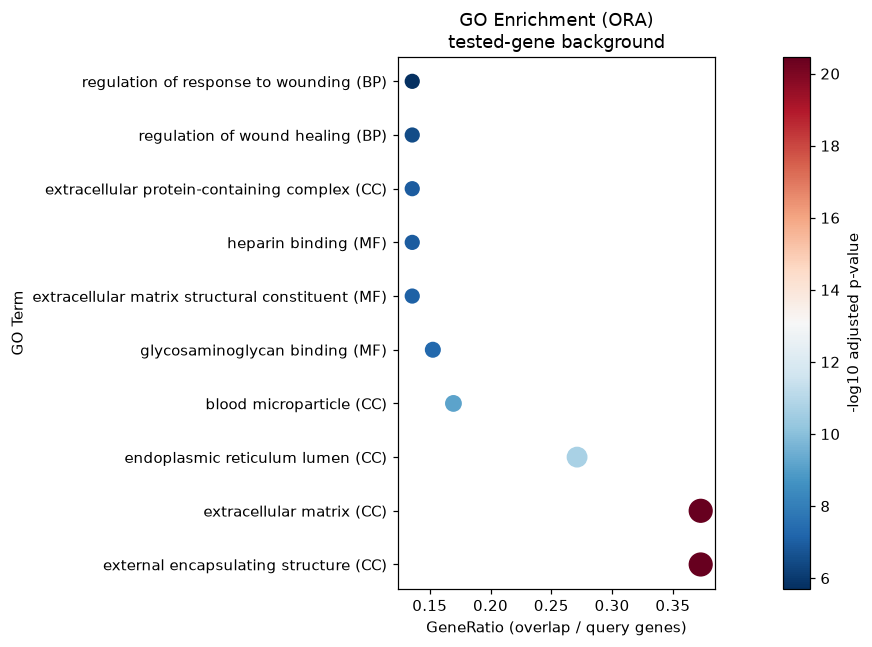

In [37]:
fig = pcp.enrichment_analysis(genes["Upregulated"] + genes["Downregulated"], organism=organism, background=genes["Background"])

In [38]:
ora.head(10)

,source,term_id,term_name,term_size,intersection_size,query_size,gene_ratio,p_value,adj_p_value
0,CC,GO:0030312,external encapsulating structure,135,22,59,0.372881,6.358748e-24,3.490953e-21
1,CC,GO:0031012,extracellular matrix,135,22,59,0.372881,6.358748e-24,3.490953e-21
2,CC,GO:0005788,endoplasmic reticulum lumen,159,16,59,0.271186,5.776212e-14,2.114094e-11
3,CC,GO:0072562,blood microparticle,48,10,59,0.169492,2.735615e-12,7.509263e-10
4,MF,GO:0005539,glycosaminoglycan binding,52,9,59,0.152542,2.172715e-10,4.771283e-08
5,MF,GO:0005201,extracellular matrix structural constituent,38,8,59,0.135593,4.474872e-10,8.189015e-08
6,MF,GO:0008201,heparin binding,41,8,59,0.135593,8.580967e-10,1.177738e-07
7,CC,GO:0140392,extracellular protein-containing complex,41,8,59,0.135593,8.580967e-10,1.177738e-07
8,BP,GO:0061041,regulation of wound healing,47,8,59,0.135593,2.720308e-09,3.318776e-07
9,BP,GO:1903034,regulation of response to wounding,59,8,59,0.135593,1.779866e-08,1.954293e-06


## Single protein and comparison

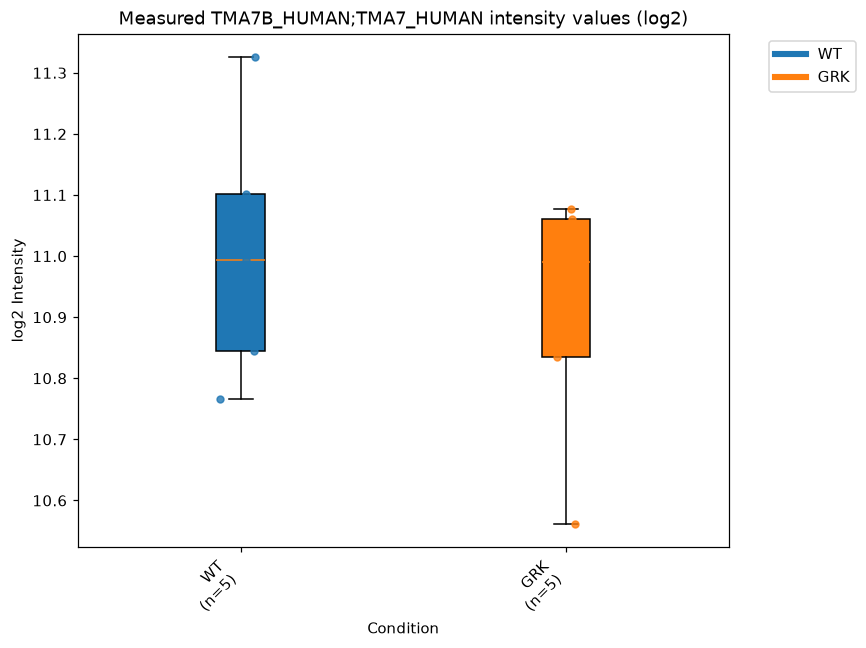

In [39]:
protein_id = str(filtered["ProteinNames"].dropna().iloc[0])
fig = pcp.boxplot_int_single_prot(filtered.set_index("ProteinNames", drop=False), meta, protein_id, dots=True)

In [40]:
protein_box = pcp.single_protein_boxplot_table(filtered, meta, "protein", protein_id, meta["condition"].unique().tolist())
protein_box.head(10)

,Condition,N,Mean,Median,Q1,Q3,Min,Max,SampleCount,SourceFeatureCount,SourceFeatures,Aggregation,Warning
0,WT,5,11.0064,10.9942,10.8444,11.1014,10.7662,11.3260,5,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
1,GRK,5,10.9050,10.9906,10.8347,11.0605,10.5617,11.0774,5,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,


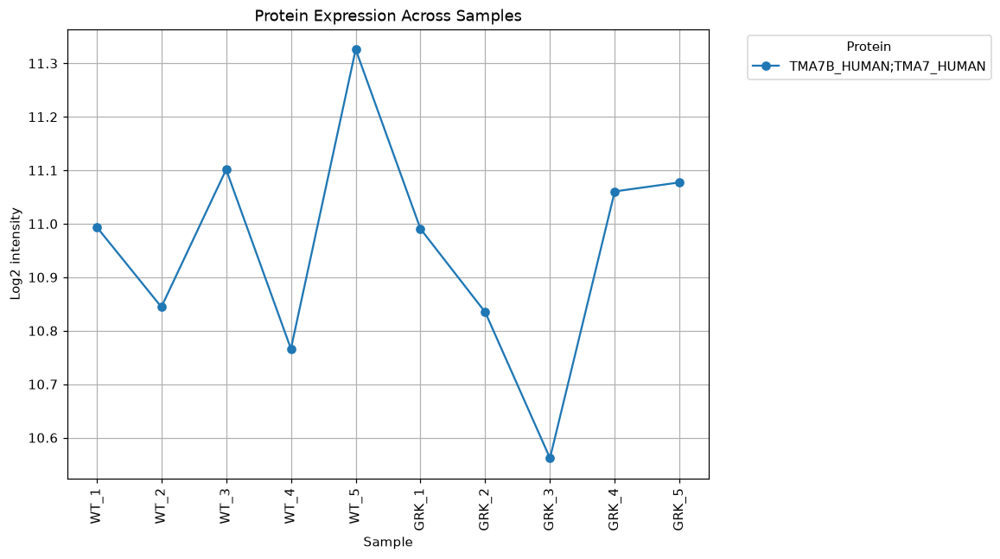

In [41]:
fig = pcp.compare_prot_line(filtered, meta, conditions, [protein_id], workflow="Protein", id=False)

In [42]:
protein_line = pcp.single_protein_lineplot_table(filtered, meta, "protein", [protein_id], conditions)
protein_line.head(10)

,Feature,Sample,Condition,Value,SampleCount,SourceFeatureCount,SourceFeatures,Aggregation,Warning
0,TMA7B_HUMAN;TMA7_HUMAN,WT_1,WT,10.9942,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
1,TMA7B_HUMAN;TMA7_HUMAN,WT_2,WT,10.8444,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
2,TMA7B_HUMAN;TMA7_HUMAN,WT_3,WT,11.1014,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
3,TMA7B_HUMAN;TMA7_HUMAN,WT_4,WT,10.7662,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
4,TMA7B_HUMAN;TMA7_HUMAN,WT_5,WT,11.3260,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
5,TMA7B_HUMAN;TMA7_HUMAN,GRK_1,GRK,10.9906,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
6,TMA7B_HUMAN;TMA7_HUMAN,GRK_2,GRK,10.8347,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
7,TMA7B_HUMAN;TMA7_HUMAN,GRK_3,GRK,10.5617,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
8,TMA7B_HUMAN;TMA7_HUMAN,GRK_4,GRK,11.0605,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
9,TMA7B_HUMAN;TMA7_HUMAN,GRK_5,GRK,11.0774,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,


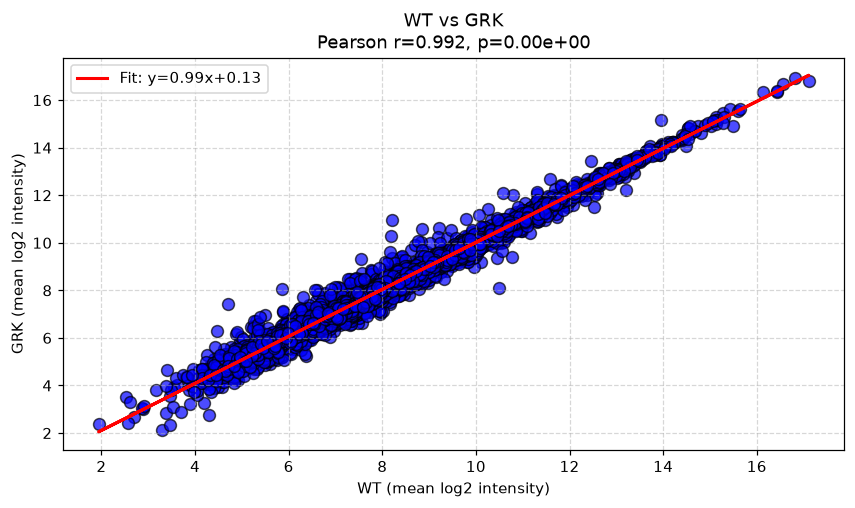

In [43]:
fig = pcp.correlation_xy_intensity(filtered, meta, *conditions)

In [44]:
pearson = pcp.pearson_table(filtered, meta, "protein", mode="Condition", condition1=conditions[0], condition2=conditions[1])
pearson.head(10)

,Metric,Value
0,Left,WT
1,Right,GRK
2,Points,7365
3,PearsonR,0.991817


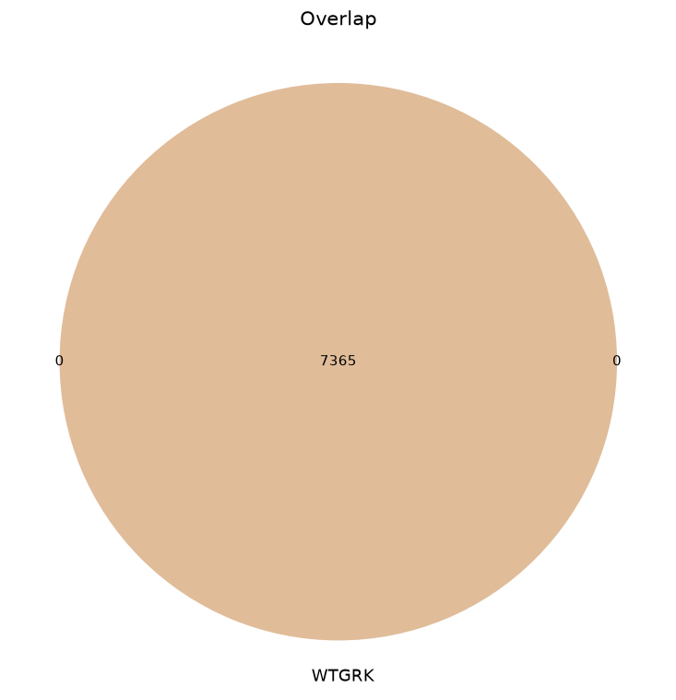

In [45]:
fig = pcp.overlap_plot_condition(filtered, meta, *conditions, data_scale="log2")

In [46]:
overlap = pcp.venn_table(filtered, meta, "protein", mode="Condition", first=conditions[0], second=conditions[1])
overlap.head(10)

,Region,Count
0,WT only,0
1,GRK only,0
2,WT & GRK,7365
3,Total WT,7365
4,Total GRK,7365


## Save protein results

In [47]:
if output_dir is not None:
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    volcano.to_csv(output_dir / "protein-volcano.csv", index=False)
    anova.to_excel(output_dir / "protein-anova.xlsx", index=False)
    pca_figure.savefig(output_dir / "protein-pca.png", dpi=300, bbox_inches="tight")
    print(f"Saved protein outputs to {output_dir.resolve()}")

## Phosphosites

In [48]:
if site_inputs is None:
    raise ValueError("Protein-only workflow is complete. Supply site_file to run the phosphosite sections.")
sites, meta_sites = read_inputs(*site_inputs)
print(f"{len(sites):,} phosphosite rows")

11,916 phosphosite rows


In [49]:
sites_filtered = pcp.filter_data(sites, meta_sites, min_present, mode=filter_mode)
sites_filtered = pcp.filter_contaminants(sites_filtered, enabled=filter_phospho_contaminants, categories=contaminant_categories)
if sites_filtered.empty:
    raise ValueError("No phosphosites remain; revise the filters.")
sites_filtered = pcp.filter_localization(sites_filtered, localization_cutoff)
if sites_filtered.empty:
    raise ValueError("No sites meet the localization cutoff.")

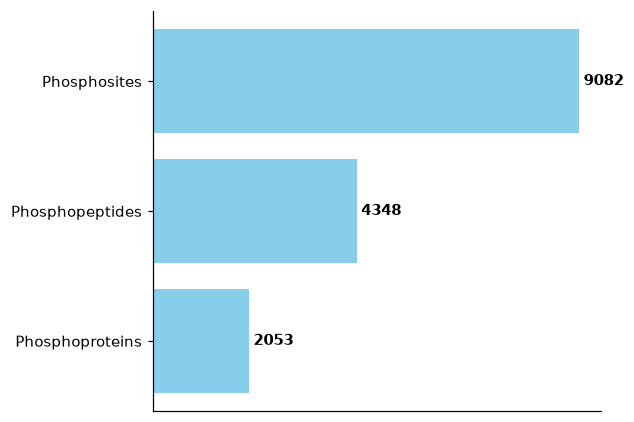

In [50]:
fig = pcp.simple_phos_site_plot(sites_filtered)

In [51]:
site_counts = pcp.phospho_counts_table(sites_filtered)
site_counts.head(10)

,Term,Count
0,Phosphosites,9082
1,Phosphopeptides,4348
2,Phosphoproteins,2053


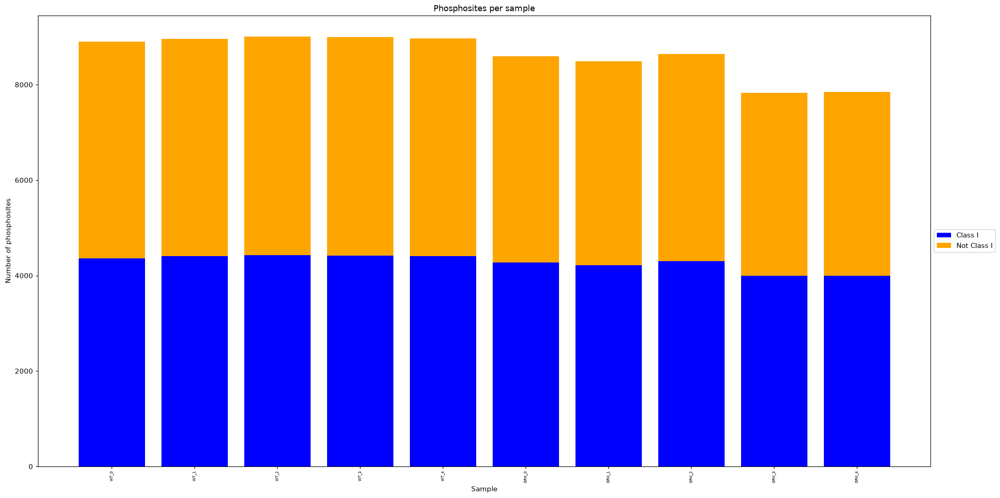

In [52]:
fig = pcp.phossite_coverage_plot(sites_filtered, meta_sites, id=False)

In [53]:
site_coverage = pcp.phospho_coverage_table(sites_filtered, meta_sites, is_log2=True)
site_coverage.head(10)

,Sample,Class I,Not Class I,Unclassified,Condition,Total
0,WT_1,4361,4544,0,WT,8905
1,WT_2,4410,4553,0,WT,8963
2,WT_3,4425,4578,0,WT,9003
3,WT_4,4420,4582,0,WT,9002
4,WT_5,4406,4566,0,WT,8972
5,GRK_1,4270,4326,0,GRK,8596
6,GRK_2,4215,4273,0,GRK,8488
7,GRK_3,4302,4344,0,GRK,8646
8,GRK_4,3994,3836,0,GRK,7830
9,GRK_5,3995,3857,0,GRK,7852


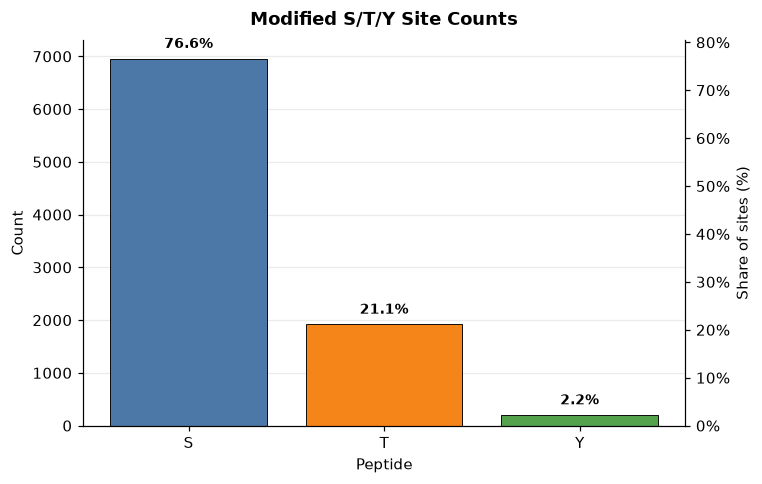

In [54]:
fig = pcp.sty_plot(sites_filtered)

In [55]:
site_residues = pcp.phospho_sty_table(sites_filtered)
site_residues.head(10)

,Residue,Count,Percentage
0,S,6958,76.61
1,T,1921,21.15
2,Y,203,2.24


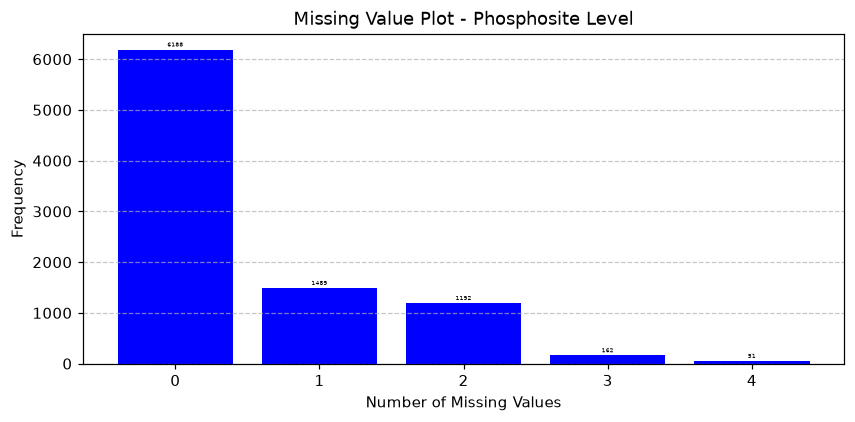

In [56]:
fig = pcp.missing_value_plot(sites_filtered, meta_sites, data_scale="log2")

In [57]:
missing_sites = pcp.missing_protein_table(sites_filtered, meta_sites, id=False)
missing_sites.head(10)

,n_MissingProteinValues,Counts,%_missing_values
0,0,6188,68.134772
1,1,1489,16.395067
2,2,1192,13.124862
3,3,162,1.783748
4,4,51,0.561550


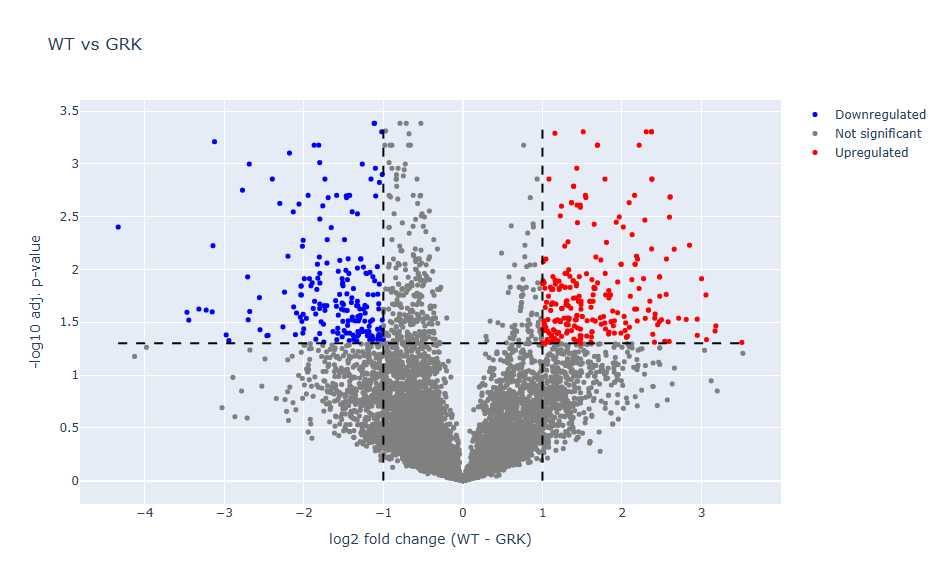

In [58]:
site_volcano = pcp.volcano_data_f(sites_filtered, meta_sites, *conditions, workflow="Phosphosite", test_type=test_type)
pcp.volcano_plot(site_volcano, *conditions).show()

In [59]:
site_volcano.head(10)

,PTM_Collapse_key,log2FC,pval,adj_pval,selected_pval,significance,neg_log10_selected_pval,zero_variance,se,dof,Protein_group
0,A0A590UK10~ARHGEF18_S1035_M1,0.277869,0.457396,0.677111,0.677111,Not significant,0.169340,False,0.353320,7.0,A0A590UK10
1,A0A590UK10~ARHGEF18_S1037_M1,0.362651,0.439661,0.662410,0.662410,Not significant,0.178873,False,0.442683,7.0,A0A590UK10
2,A0JLT2~MED19_S226_M1,-0.502388,0.033772,0.157452,0.157452,Not significant,0.802852,False,0.196428,8.0,A0JLT2
3,A0JNW5~BLTP3B_S418_M1,-0.385220,0.607367,0.779661,0.779661,Not significant,0.108094,False,0.716258,7.0,A0JNW5
4,A0JNW5~BLTP3B_S951_M1,0.471039,0.576060,0.760211,0.760211,Not significant,0.119066,False,0.796952,6.0,A0JNW5
5,A0JNW5~BLTP3B_S987_M1,1.107601,0.041386,0.175967,0.175967,Not significant,0.754568,False,0.428164,6.0,A0JNW5
6,A0JNW5~BLTP3B_S989_M1,0.421164,0.244273,0.479362,0.479362,Not significant,0.319337,False,0.331317,7.0,A0JNW5
7,A0JNW5~BLTP3B_T420_M1,0.783011,0.015246,0.099399,0.099399,Not significant,1.002616,False,0.245347,7.0,A0JNW5
8,A0MZ66~SHTN1_S492_M1,-0.194668,0.642098,0.800952,0.800952,Not significant,0.096394,False,0.403115,8.0,A0MZ66
9,A0MZ66~SHTN1_S493_M1,-0.045639,0.902846,0.954524,0.954524,Not significant,0.020213,False,0.362236,8.0,A0MZ66


In [60]:
phospho_untested = pcp.volcano_untested_table(sites_filtered, meta_sites, *conditions, kind="phospho", paired=test_type == "paired")
phospho_untested.head(10)

,PTM_Collapse_key,Gene_group,UPD_seq,Protein_group,n_WT,mean_WT,n_GRK,mean_GRK,reason


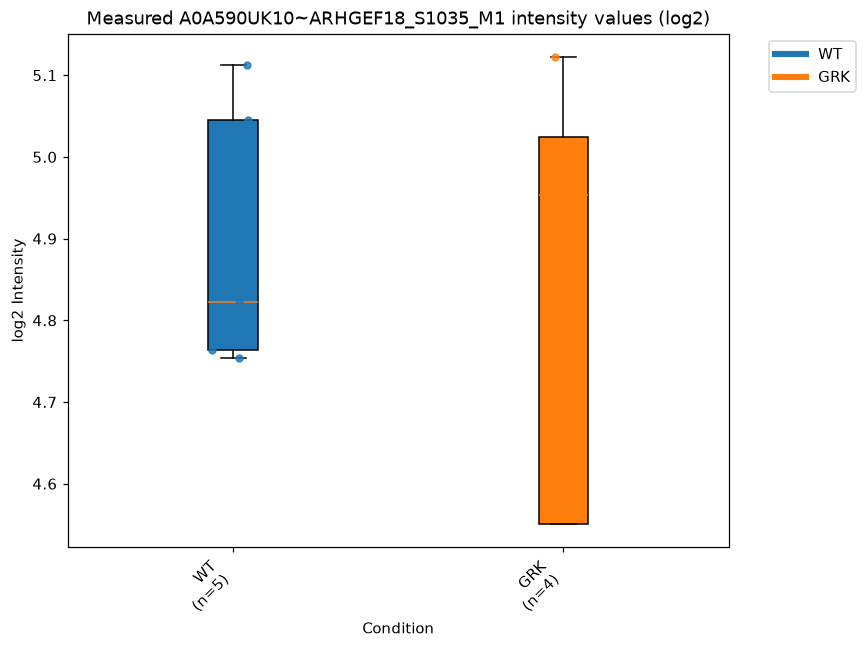

In [61]:
site_id = str(sites_filtered["PTM_Collapse_key"].dropna().iloc[0])
fig = pcp.boxplot_int_single_prot(sites_filtered.set_index("PTM_Collapse_key", drop=False), meta_sites, site_id, dots=True)

In [62]:
site_box = pcp.single_protein_boxplot_table(sites_filtered, meta_sites, "phospho", site_id, meta_sites["condition"].unique().tolist())
site_box.head(10)

,Condition,N,Mean,Median,Q1,Q3,Min,Max,SampleCount,SourceFeatureCount,SourceFeatures,Aggregation,Warning
0,WT,5,4.8996,4.8221,4.7643,5.0456,4.7540,5.1119,5,1,A0A590UK10~ARHGEF18_S1035_M1,Per-sample median,
1,GRK,4,4.6217,4.9536,4.5509,5.0244,3.4572,5.1224,4,1,A0A590UK10~ARHGEF18_S1035_M1,Per-sample median,


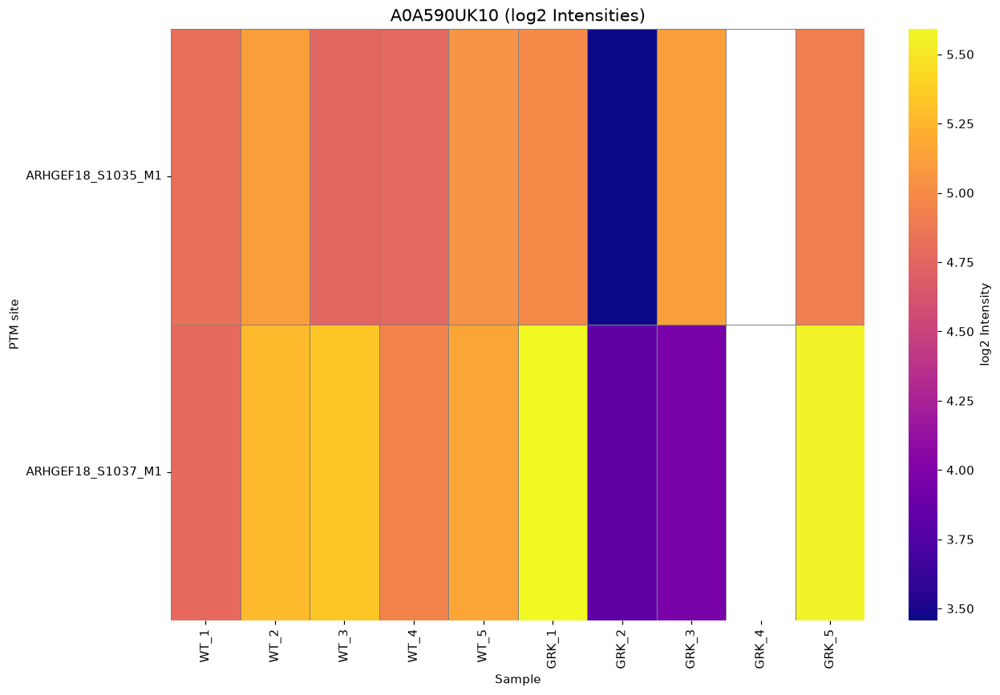

In [63]:
protein_of_site = str(sites_filtered["Protein_group"].dropna().iloc[0]).split(";")[0].strip()
fig = pcp.phossite_on_prot_regulation(sites_filtered, meta_sites, protein_of_site, conditions=conditions, id=False)

In [64]:
site_heatmap = pcp.single_protein_heatmap_table(sites_filtered, meta_sites, "phospho", protein_of_site, conditions, filter_m1=False)
site_heatmap.head(10)

,Site,PTM_Collapse_key,WT_1,WT_2,WT_3,WT_4,WT_5,GRK_1,GRK_2,GRK_3,GRK_4,GRK_5
0,ARHGEF18_S1035_M1,A0A590UK10~ARHGEF18_S1035_M1,4.8221,5.1119,4.7540,4.7643,5.0456,4.9918,3.4572,5.1224,NaN,4.9155
1,ARHGEF18_S1037_M1,A0A590UK10~ARHGEF18_S1037_M1,4.7836,5.2708,5.3409,4.9519,5.1544,5.5932,3.8295,3.9646,NaN,5.5634


## Phosphoproteins

In [65]:
phosprot = pcp.transform_phosprot(sites_filtered, meta_sites, mode="robust_site_median",
                                 data_scale="log2", coverage_data=sites_filtered)
phosprot_filtered = pcp.filter_data(phosprot, meta_sites, min_present, mode=filter_mode)
phosprot_filtered = pcp.filter_contaminants(phosprot_filtered, enabled=filter_phospho_contaminants,
                                           categories=contaminant_categories)
print(f"{len(sites_filtered):,} retained sites; {len(phosprot_filtered):,} phosphoproteins after filtering")

9,082 retained sites; 2,053 phosphoproteins after filtering


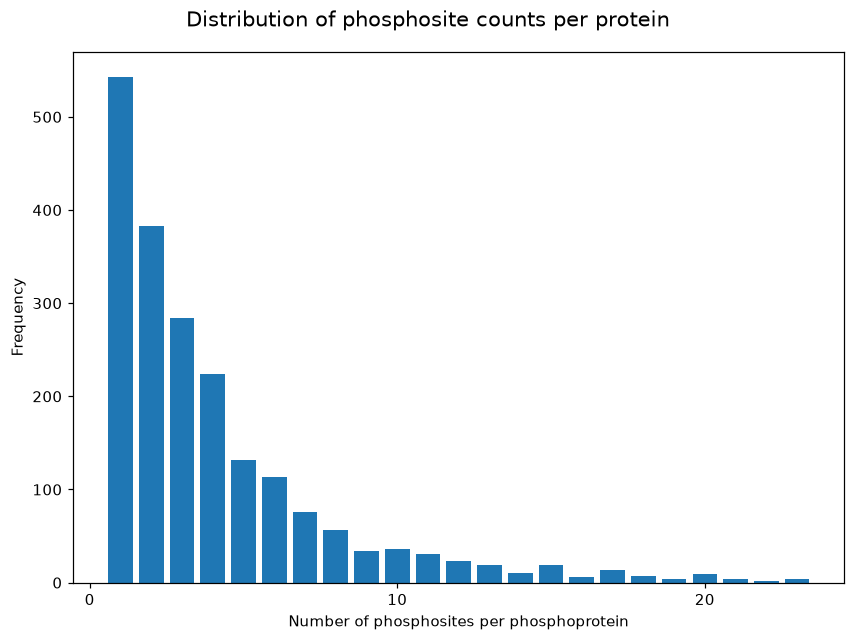

In [66]:
fig = pcp.phossite_dist(phosprot_filtered, cutoff=0.01)

In [67]:
site_distribution = pcp.phospho_distribution_table(phosprot_filtered, cutoff=0.01)
site_distribution

,SiteCount,Frequency
0,1,543
1,2,383
2,3,284
3,4,224
4,5,132
5,6,113
...,...,...
17,18,7
18,19,4
19,20,9


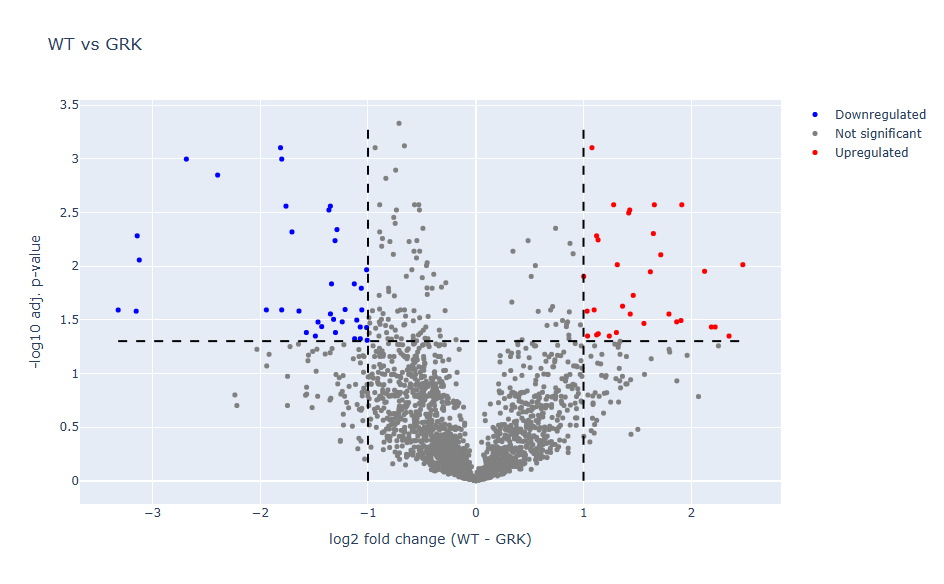

In [68]:
phosprot_volcano = pcp.volcano_data_f(phosprot_filtered, meta_sites, *conditions, workflow="Phosphoprotein", test_type=test_type)
fig = pcp.volcano_plot(phosprot_volcano, *conditions)
fig.show()

In [69]:
phosprot_volcano.head(10)

,Phosphoprotein,log2FC,pval,adj_pval,selected_pval,significance,neg_log10_selected_pval,...,n_partially_imputed__WT,n_imputed__WT,n_measured__GRK,n_fully_imputed__GRK,n_partially_imputed__GRK,n_imputed__GRK,imputed_values
0,A0A590UK10,0.320260,0.388686,0.605902,0.605902,Not significant,0.217598,...,0,0,4,0,0,0,0
1,A0JLT2,-0.502388,0.033772,0.147519,0.147519,Not significant,0.831153,...,0,0,5,0,0,0,0
2,A0JNW5,0.441035,0.161611,0.362609,0.362609,Not significant,0.440561,...,0,0,5,0,0,0,0
3,A0MZ66,-0.061016,0.840079,0.918361,0.918361,Not significant,0.036987,...,0,0,5,0,0,0,0
4,A1L170,0.360363,0.420698,0.633671,0.633671,Not significant,0.198136,...,0,0,4,0,0,0,0
5,A1L390,-0.777708,0.010595,0.077134,0.077134,Not significant,1.112753,...,0,0,5,0,0,0,0
6,A1X283,-0.375604,0.474821,0.682638,0.682638,Not significant,0.165810,...,0,0,3,0,0,0,0
7,A2RRP1,-0.120032,0.846982,0.921003,0.921003,Not significant,0.035739,...,0,0,4,0,0,0,0
8,A3KMH1,0.348131,0.324290,0.543484,0.543484,Not significant,0.264813,...,0,0,4,0,0,0,0
9,A4D1P6,-0.426872,0.378311,0.595152,0.595152,Not significant,0.225372,...,0,0,5,0,0,0,0


In [70]:
phosprot_untested = pcp.volcano_untested_table(phosprot_filtered, meta_sites, *conditions, kind="phosprot", paired=test_type == "paired")
phosprot_untested.head(10)

,Phosphoprotein,Gene_group,UPD_seq,site_num,PTM_Collapse_keys,n_WT,mean_WT,n_GRK,mean_GRK,reason


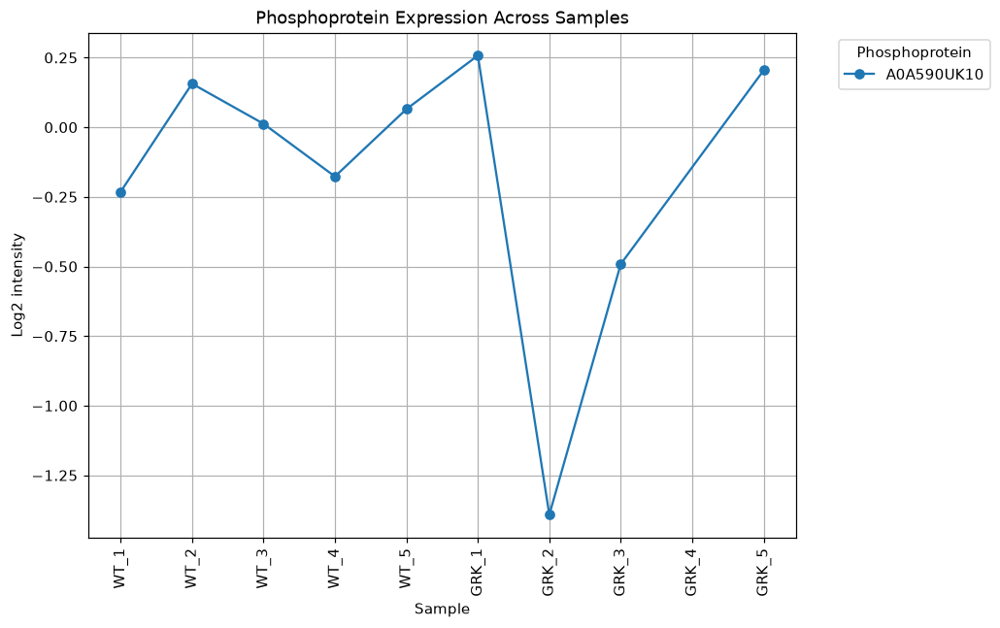

In [71]:
phosprot_id = str(phosprot_filtered["Phosphoprotein"].dropna().iloc[0])
fig = pcp.compare_prot_line(phosprot_filtered, meta_sites, conditions, [phosprot_id], workflow="Phosphoprotein", id=False)

In [72]:
phosprot_line = pcp.single_protein_lineplot_table(phosprot_filtered, meta_sites, "phosprot", [phosprot_id], conditions)
phosprot_line.head(10)

,Feature,Sample,Condition,Value,SampleCount,SourceFeatureCount,SourceFeatures,Aggregation,Warning
0,A0A590UK10,WT_1,WT,-0.2321,9,1,A0A590UK10,Per-sample median,
1,A0A590UK10,WT_2,WT,0.1564,9,1,A0A590UK10,Per-sample median,
2,A0A590UK10,WT_3,WT,0.0125,9,1,A0A590UK10,Per-sample median,
3,A0A590UK10,WT_4,WT,-0.1768,9,1,A0A590UK10,Per-sample median,
4,A0A590UK10,WT_5,WT,0.0651,9,1,A0A590UK10,Per-sample median,
5,A0A590UK10,GRK_1,GRK,0.2576,9,1,A0A590UK10,Per-sample median,
6,A0A590UK10,GRK_2,GRK,-1.3916,9,1,A0A590UK10,Per-sample median,
7,A0A590UK10,GRK_3,GRK,-0.4915,9,1,A0A590UK10,Per-sample median,
8,A0A590UK10,GRK_4,GRK,NaN,9,1,A0A590UK10,Per-sample median,
9,A0A590UK10,GRK_5,GRK,0.2045,9,1,A0A590UK10,Per-sample median,


In [73]:
if output_dir is not None:
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    site_volcano.to_csv(output_dir / "phosphosite-volcano.csv", index=False)
    phosprot_volcano.to_csv(output_dir / "phosphoprotein-volcano.csv", index=False)